# Exploratory data analysis

In [1]:
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Work from the project root whether the notebook is opened from notebooks/ or the root.
if Path.cwd().name == "notebooks":
    os.chdir("..")

DATA = Path("data/processed")
PROJECTS = ["tinydb", "toolz", "boltons"]
pd.set_option("display.precision", 4)

## 1. Load the data

For each project: Kalman duration estimates, the 10 raw timing runs, and the per-test coverage map (`file:line` IDs).

In [2]:
def load(project):
    kalman = pd.read_csv(DATA / f"{project}_kalman_estimates.csv")
    runs = pd.read_csv(DATA / f"{project}_timing_runs.csv")
    cov = pd.read_csv(DATA / f"{project}_coverage_matrix.csv")

    coverage = {}
    for row in cov.itertuples():
        lines = {f"{row.source_file}:{l}" for l in str(row.covered_lines).split(";") if l}
        coverage.setdefault(row.test_node_id, set()).update(lines)

    return kalman, runs, coverage


data = {p: load(p) for p in PROJECTS}

overview = pd.DataFrame([
    {
        "project": p,
        "tests_timed": len(k),
        "tests_with_coverage": len(c),
        "coverable_lines": len(set().union(*c.values())),
        "full_suite_seconds": k["kalman_estimate_seconds"].sum(),
    }
    for p, (k, r, c) in data.items()
])
overview

,project,tests_timed,tests_with_coverage,coverable_lines,full_suite_seconds
0,tinydb,228,227,499,0.4798
1,toolz,193,190,1036,0.9055
2,boltons,620,586,4368,3.7402


## 2. Test durations

Durations span about four orders of magnitude, so they are plotted on a log scale. A handful of slow tests take most of the time.

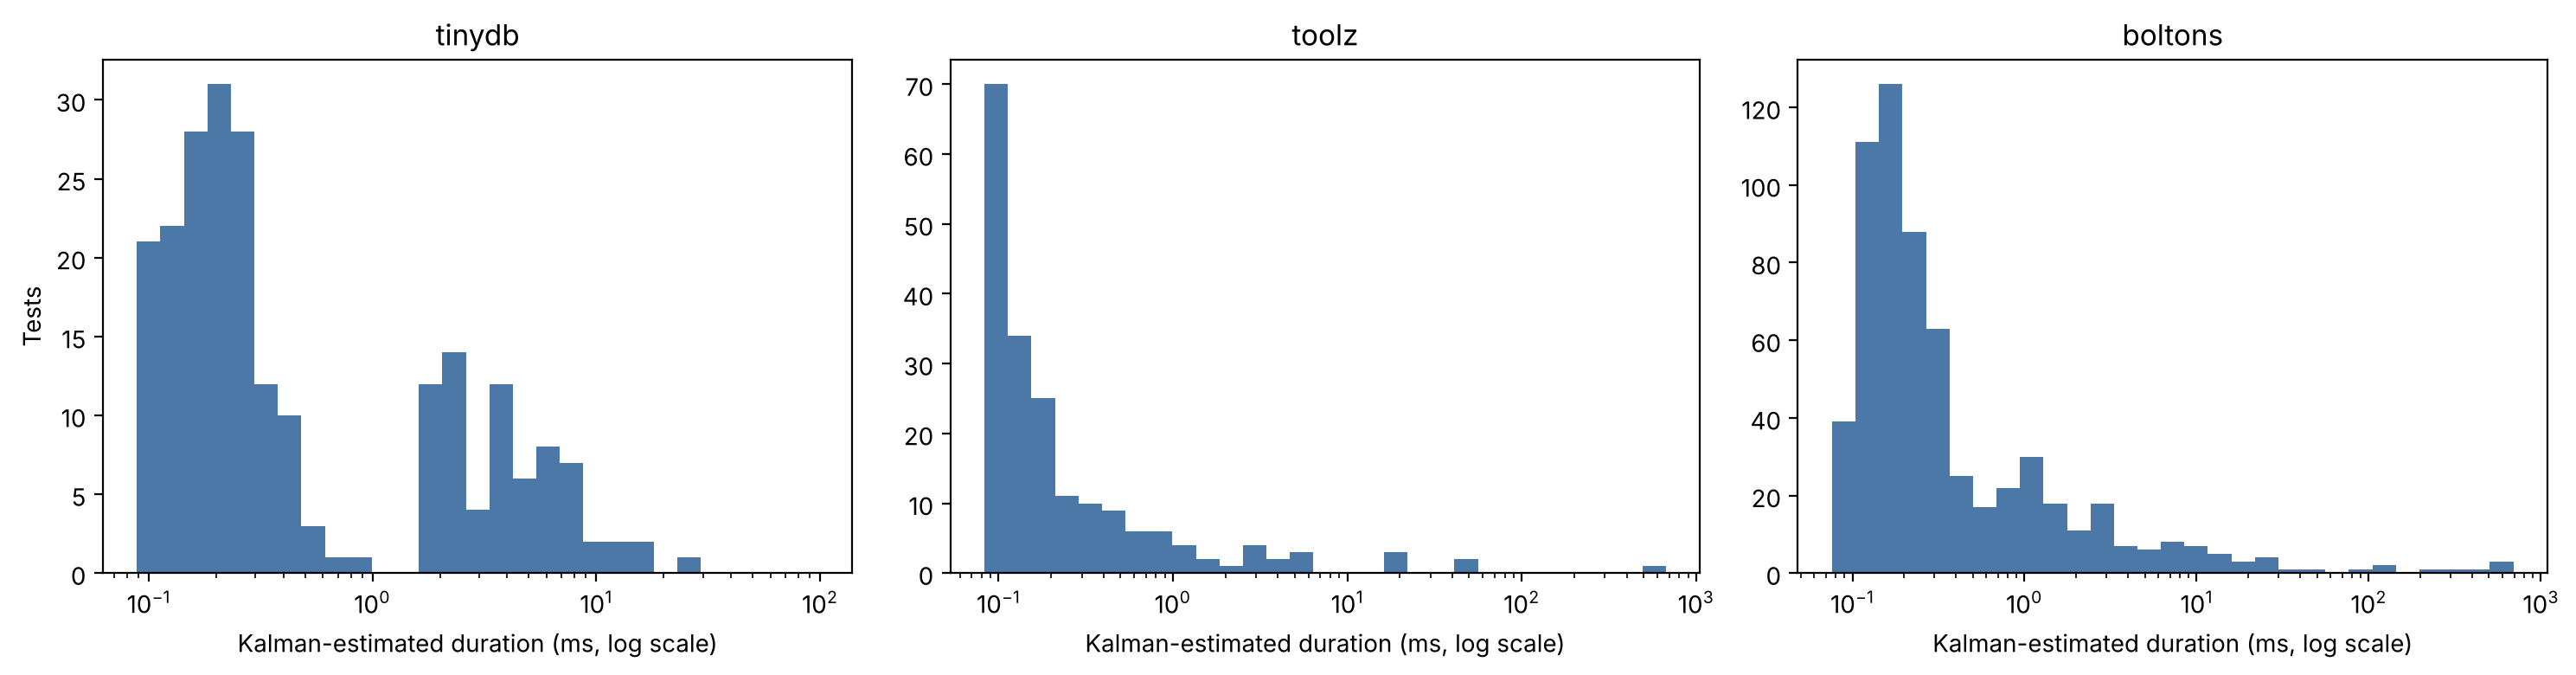

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, p in zip(axes, PROJECTS):
    d = data[p][0]["kalman_estimate_seconds"] * 1000
    ax.hist(d, bins=np.logspace(np.log10(d.min()), np.log10(d.max()), 30), color="#4C78A8")
    ax.set_xscale("log")
    ax.set_title(p)
    ax.set_xlabel("Kalman-estimated duration (ms, log scale)")
axes[0].set_ylabel("Tests")
plt.tight_layout()
plt.show()

In [4]:
def duration_summary(p):
    d = data[p][0]["kalman_estimate_seconds"].sort_values(ascending=False)
    top_n = max(1, int(len(d) * 0.05))
    return {
        "project": p,
        "median_ms": d.median() * 1000,
        "p95_ms": d.quantile(0.95) * 1000,
        "max_ms": d.max() * 1000,
        "share_of_time_in_slowest_5pct": d.head(top_n).sum() / d.sum(),
    }

pd.DataFrame([duration_summary(p) for p in PROJECTS])

,project,median_ms,p95_ms,max_ms,share_of_time_in_slowest_5pct
0,tinydb,0.2475,8.1029,98.2902,0.4694
1,toolz,0.1417,3.8470,671.2552,0.9285
2,boltons,0.2198,7.9552,692.5335,0.9038


### Timing noise

The coefficient of variation (standard deviation / mean) over the 10 runs shows how much a single timing can mislead. This is why the optimisers use Kalman-filtered durations.

In [5]:
rows = []
for p in PROJECTS:
    runs = data[p][1]
    runs = runs[runs["status"] == "passed"]
    stats = runs.groupby("node_id")["duration_seconds"].agg(["mean", "std"])
    cv = stats["std"] / stats["mean"]
    rows.append({"project": p, "median_cv": cv.median(), "tests_with_cv_over_0.5": int((cv > 0.5).sum())})
pd.DataFrame(rows)

,project,median_cv,tests_with_cv_over_0.5
0,tinydb,0.3035,11
1,toolz,0.3302,29
2,boltons,0.3151,64


## 3. Coverage overlap between tests

For each line we count how many tests cover it. Lines covered by many tests are where a selection can safely drop tests; lines covered by **exactly one** test are lost if that test is dropped.

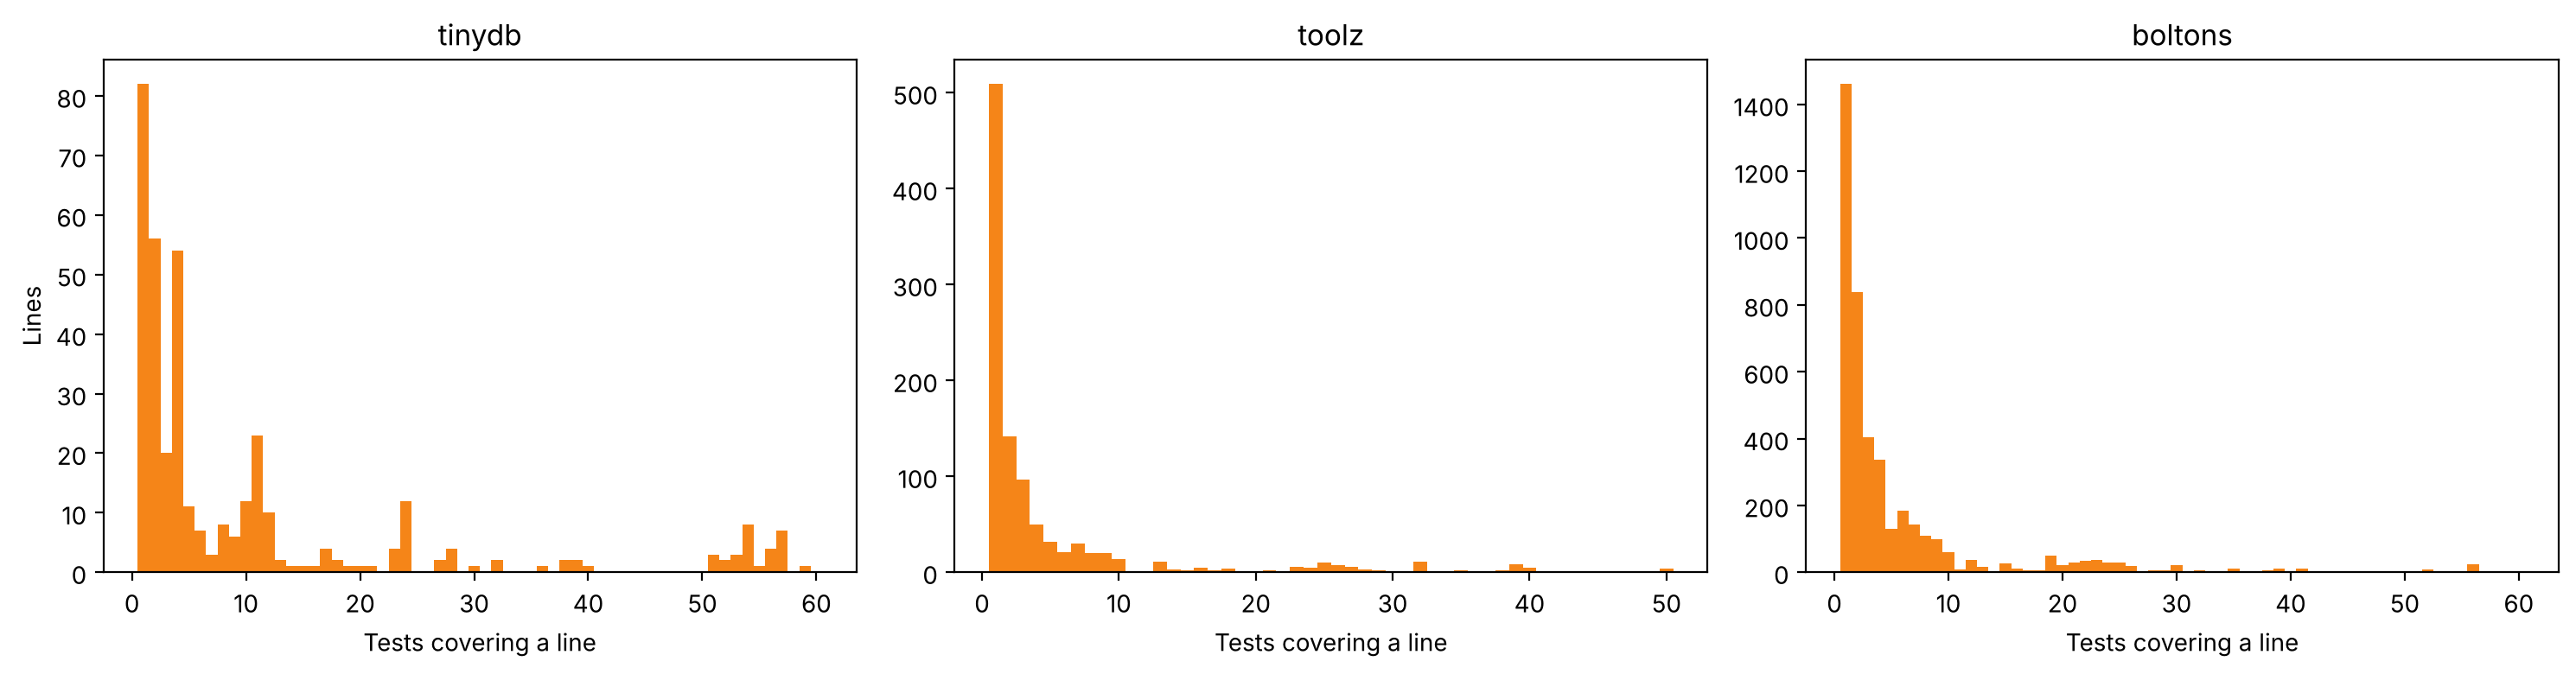

,project,lines,median_tests_per_line,lines_covered_by_one_test,share_covered_by_one_test
0,tinydb,499,10.0,82,0.1643
1,toolz,1036,2.0,509,0.4913
2,boltons,4368,2.0,1461,0.3345


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
redundancy = []
for ax, p in zip(axes, PROJECTS):
    coverage = data[p][2]
    per_line = pd.Series([line for lines in coverage.values() for line in lines]).value_counts()
    ax.hist(per_line, bins=np.arange(1, min(per_line.max(), 60) + 2) - 0.5, color="#F58518")
    ax.set_title(p)
    ax.set_xlabel("Tests covering a line")
    redundancy.append({
        "project": p,
        "lines": len(per_line),
        "median_tests_per_line": per_line.median(),
        "lines_covered_by_one_test": int((per_line == 1).sum()),
        "share_covered_by_one_test": (per_line == 1).mean(),
    })
axes[0].set_ylabel("Lines")
plt.tight_layout()
plt.show()
pd.DataFrame(redundancy)

### Pairwise overlap

The Jaccard similarity of two tests is |lines in both| / |lines in either|. A high share of near-duplicate pairs means many tests can be removed without losing coverage.

In [7]:
def jaccard_stats(coverage, max_tests=300, seed=0):
    tests = [t for t, lines in coverage.items() if lines]
    rng = np.random.default_rng(seed)
    if len(tests) > max_tests:
        tests = list(rng.choice(tests, max_tests, replace=False))
    values = []
    for i in range(len(tests)):
        a = coverage[tests[i]]
        for j in range(i + 1, len(tests)):
            b = coverage[tests[j]]
            values.append(len(a & b) / len(a | b))
    values = np.array(values)
    return {"pairs": len(values), "mean_jaccard": values.mean(),
            "pairs_over_0.8": (values > 0.8).mean(), "pairs_with_no_overlap": (values == 0).mean()}

pd.DataFrame([{"project": p, **jaccard_stats(data[p][2])} for p in PROJECTS])

,project,pairs,mean_jaccard,pairs_over_0.8,pairs_with_no_overlap
0,tinydb,25651,0.3178,0.0386,0.1839
1,toolz,17955,0.0343,0.0084,0.8511
2,boltons,44850,0.0337,0.0078,0.9169


## 4. Coverage against cost

Each dot is a test. Tests in the top-left (cheap, many lines) are what greedy picks first; tests on the right cost a lot of budget.

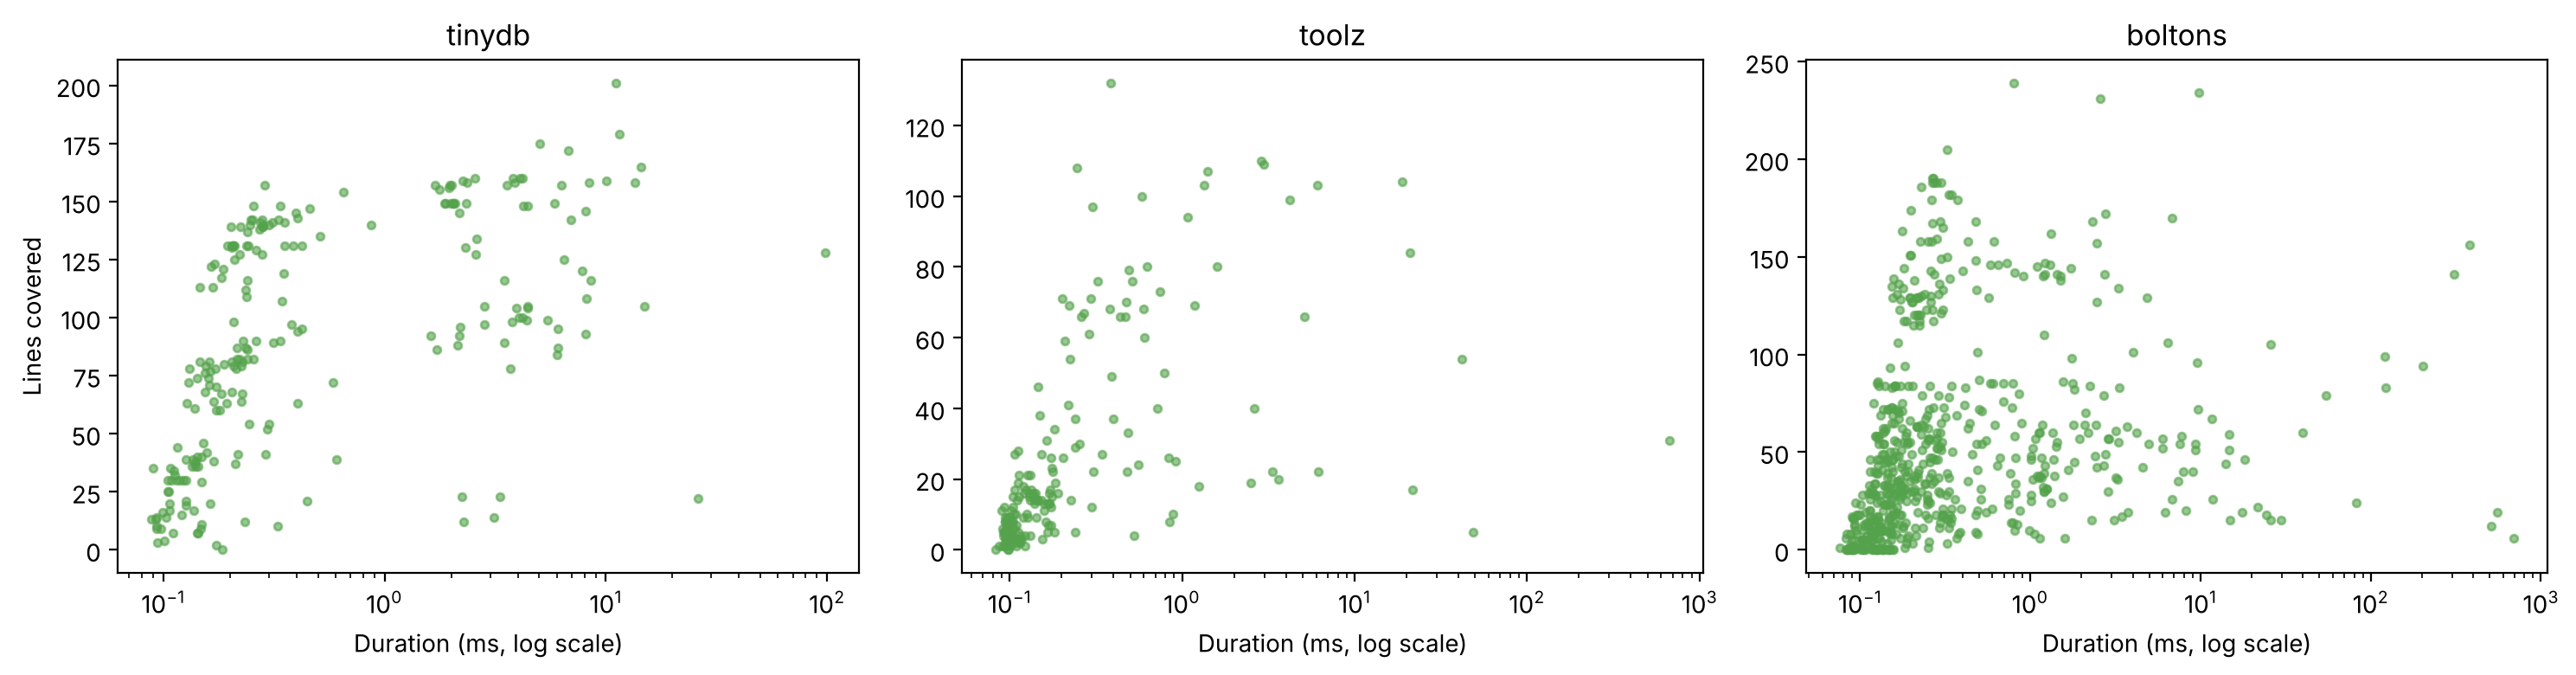

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, p in zip(axes, PROJECTS):
    kalman, _, coverage = data[p]
    df = kalman.assign(lines=kalman["test_node_id"].map(lambda t: len(coverage.get(t, ()))))
    ax.scatter(df["kalman_estimate_seconds"] * 1000, df["lines"], s=10, alpha=0.6, color="#54A24B")
    ax.set_xscale("log")
    ax.set_title(p)
    ax.set_xlabel("Duration (ms, log scale)")
axes[0].set_ylabel("Lines covered")
plt.tight_layout()
plt.show()

## 5. What this means for the optimisers

- **Time is concentrated in a few tests.** The slowest 5% of tests take 47% of TinyDB's suite time and about 90% of toolz's and boltons'. Leaving those out frees most of the budget, which is why even a 5-10% budget keeps high coverage.
- **Redundancy differs by project.** TinyDB's lines are covered by a median of 10 tests, so many tests can go with no coverage loss. In toolz and boltons the median is 2, and 33-49% of lines are covered by only one test; a selection keeps those lines only by keeping that specific test, which makes tight budgets harder.
- **Single timings are unreliable.** The median coefficient of variation over 10 runs is 0.30-0.33, so one run can be a third off. The optimisers therefore use Kalman-filtered durations.